# Eight-case pilot: random-context benchmark

## tl;dr
This is the random-control condition of an eight-case exploratory pilot. It samples 128 labeled examples at random from the frozen source and compares XGBoost with SAP RPT on the same 128 held-out invoices used by the after stage.

## Context & methods
Source: `data/semantic_ablation/source_snapshot.csv`. Random rows are drawn from the first 1,024 invoices; the final 128 are held out. Saved SAP runs come from `data/context_benchmark/selection_holdout_*`. The [original 22-case run](../before_context_engineering/README.md) uses different fraud labels and is the main presentation baseline.

Both models use the same 128-row selected training/context IDs per target and seed, and predict the same frozen 128-invoice holdout. Five seeds vary the selected examples; the holdout itself is fixed. SAP RPT results are saved predictions; XGBoost is reproduced locally. No live SAP call is made.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
from context_engineering import select_context, assert_no_leakage
from run_context_benchmark import xgb_predict, metric_row

source = pd.read_csv(ROOT / 'data/semantic_ablation/source_snapshot.csv')
pool, holdout = source.iloc[:1024].copy(), source.iloc[1024:].copy()
sap_results = pd.read_csv(ROOT / 'data/context_benchmark/selection_holdout_results.csv')
sap_predictions = pd.read_csv(ROOT / 'data/context_benchmark/selection_holdout_predictions.csv')
targets = {'paid_late': 'Late payment', 'is_fraud': 'Fraud'}
seeds = (11, 23, 37, 41, 53)
assert len(source) == 1152 and len(holdout) == 128 and holdout.is_fraud.sum() == 8
assert_no_leakage(pool, holdout)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})


ModuleNotFoundError: No module named 'dotenv'

## Results

### Select rows and verify model predictions

In [ ]:
strategy = 'random'
xgb_rows = []
xgb_predictions = []
for target in targets:
    for seed in seeds:
        context, _ = select_context(pool, target, holdout.iloc[:1], strategy, 128, seed)
        assert_no_leakage(context, holdout)
        predicted, _, _, _ = xgb_predict(context, holdout, target, seed)
        xgb_rows.append({'model': 'XGBoost', 'target': target, 'strategy': strategy,
                         'seed': seed, 'context_positives': int(context[target].sum()),
                         **metric_row(holdout[target].to_numpy(), predicted)})
        xgb_predictions.extend({'model': 'XGBoost', 'target': target, 'seed': seed,
                                'invoice_id': invoice_id, 'actual': int(actual),
                                'predicted': int(prediction)}
                               for invoice_id, actual, prediction in
                               zip(holdout.invoice_id, holdout[target], predicted))

xgb = pd.DataFrame(xgb_rows)
xgb_predictions = pd.DataFrame(xgb_predictions)
sap = sap_results[(sap_results.model == 'SAP-RPT') &
                  (sap_results.strategy == strategy)].copy()
assert len(xgb) == len(sap) == 10
matched = xgb.merge(sap[['target', 'seed', 'context_positives']],
                    on=['target', 'seed'], suffixes=('_xgb', '_sap'))
assert len(matched) == 10
assert matched.context_positives_xgb.equals(matched.context_positives_sap)

saved_predictions = sap_predictions[sap_predictions.run_id.isin(sap.run_id)]
assert len(saved_predictions) == len(sap) * len(holdout)
for result in sap.itertuples():
    rows = saved_predictions[saved_predictions.run_id == result.run_id]
    assert set(rows.invoice_id) == set(holdout.invoice_id)
    checked = metric_row(rows.actual.to_numpy(), rows.predicted.to_numpy())
    assert np.isclose(checked['f1'], result.f1)
    assert checked['true_positives'] == result.true_positives
    assert checked['false_positives'] == result.false_positives

results = pd.concat([xgb, sap], ignore_index=True)
results['Target'] = results.target.map(targets)
summary = (results.groupby(['Target', 'model'])
           .agg(F1=('f1', 'mean'), F1_seed_SD=('f1', 'std'),
                Precision=('precision', 'mean'), Recall=('recall', 'mean'),
                True_positives=('true_positives', 'mean'),
                False_positives=('false_positives', 'mean'),
                Positive_context_rows=('context_positives', 'mean')))
display(summary.round(3))


F1  F1_seed_SD  ...  False_positives  Positive_context_rows
Target       model                       ...                                        
Fraud        SAP-RPT  0.000       0.000  ...              0.0                    5.4
             XGBoost  0.027       0.060  ...              3.8                    5.4
Late payment SAP-RPT  0.544       0.031  ...             24.6                   54.0
             XGBoost  0.565       0.041  ...             27.0                   54.0

[4 rows x 7 columns]

### Visual comparison
F1 error bars show standard deviation across the five context seeds. Fraud detection and false-alarm bars show means per 128-invoice holdout.

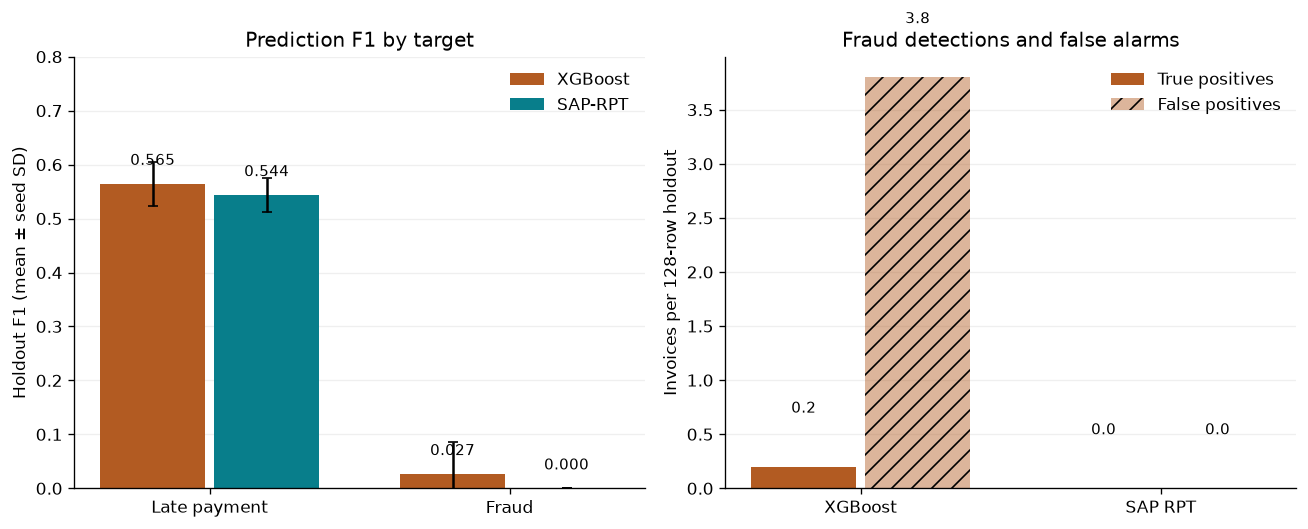

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = {'XGBoost': '#b25b22', 'SAP-RPT': '#087e8b'}
for index, (target, label) in enumerate(targets.items()):
    for model, offset in [('XGBoost', -0.19), ('SAP-RPT', 0.19)]:
        values = results[(results.target == target) & (results.model == model)].f1
        x = index + offset
        axes[0].bar(x, values.mean(), width=0.35, yerr=values.std(),
                    capsize=3, color=colors[model], label=model)
        axes[0].text(x, values.mean() + 0.035, f'{values.mean():.3f}',
                     ha='center', fontsize=9)
axes[0].set_xticks([0, 1], list(targets.values()))
axes[0].set_ylabel('Holdout F1 (mean ± seed SD)')
axes[0].set_ylim(0, 0.8)
axes[0].set_title('Prediction F1 by target')
axes[0].grid(axis='y', alpha=0.2)
axes[0].set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles[:2], labels[:2], frameon=False)

fraud = results[results.target == 'is_fraud'].groupby('model')
for index, model in enumerate(['XGBoost', 'SAP-RPT']):
    values = fraud.get_group(model)
    axes[1].bar(index - 0.19, values.true_positives.mean(), width=0.35,
                color=colors[model], label='True positives' if index == 0 else None)
    axes[1].bar(index + 0.19, values.false_positives.mean(), width=0.35,
                color=colors[model], alpha=0.45, hatch='//',
                label='False positives' if index == 0 else None)
    axes[1].text(index - 0.19, values.true_positives.mean() + 0.5,
                 f'{values.true_positives.mean():.1f}', ha='center', fontsize=9)
    axes[1].text(index + 0.19, values.false_positives.mean() + 0.5,
                 f'{values.false_positives.mean():.1f}', ha='center', fontsize=9)
axes[1].set_xticks([0, 1], ['XGBoost', 'SAP RPT'])
axes[1].set_ylabel('Invoices per 128-row holdout')
axes[1].set_title('Fraud detections and false alarms')
axes[1].legend(frameon=False)
axes[1].grid(axis='y', alpha=0.2)
axes[1].set_axisbelow(True)
fig.tight_layout()
plt.show()


## Takeaways
Random context contains few fraud positives, so both models detect few fraud cases. Read precision, recall, F1 and false positives together. The [after benchmark](02_balanced_context_benchmark.ipynb) changes only the selected examples on this same frozen dataset.